# Experiment 3 — Results and prediction analysis
Read the saved experiment; this notebook does not train models.
**C0 versus C1** checks that the inactive coordinate preserves the function.
**C1 versus C2** measures the effect of active, irrelevant variation.
Equal supplied dimensions do not equalize informative dimensions.

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# Works when Jupyter starts inside experiment_3 or its parent project folder.
ROOT = Path.cwd()
if not (ROOT / 'experiment.py').exists():
    ROOT = ROOT / 'experiment_3'
assert (ROOT / 'experiment.py').exists(), 'Start Jupyter in experiment_3 or its parent folder.'
sys.path.insert(0, str(ROOT))
from experiment import (DATASETS, CONDITIONS, ALPHAS, SEEDS, make_splits, input_data,
    make_model, make_base, complex_columns, initial_checks, classification_metrics,
    conflict_metrics, counterfactual_metrics, train_model, compare_snapshots,
    settings, save_splits, save_json, save_rows, baseline_data, make_baseline,
    INITIAL_TOLERANCE, TRAJECTORY_TOLERANCE)

# Small matrix operations are usually faster with one CPU thread here.
torch.set_num_threads(1)
splits = make_splits()
print('Experiment folder:', ROOT)
print('PyTorch:', torch.__version__)

Experiment folder: c:\Users\ESHAAN\HAKUR\SimpBias\experiment_3
PyTorch: 2.14.1+cpu


In [2]:
READ_PREVIEW = False  # Match QUICK_RUN in Notebooks 01 and 02.
RESULTS = ROOT / 'results' / 'preview' if READ_PREVIEW else ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
metadata = json.loads((RESULTS / 'metadata.json').read_text())
baseline_settings = json.loads((RESULTS / 'baseline_settings.json').read_text())
assert metadata['status'] == baseline_settings['status'] == 'complete', 'Finish both training notebooks.'
assert metadata['quick'] == READ_PREVIEW
for key in ['seeds','steps','lr','quick']:
    assert metadata[key] == baseline_settings[key], f'Baseline/sweep mismatch: {key}'
final = pd.read_csv(RESULTS / 'summary.csv')
history = pd.read_csv(RESULTS / 'all_runs.csv')
baseline = pd.read_csv(RESULTS / 'feature_only.csv')
checks = pd.read_csv(RESULTS / 'trajectory_checks.csv')
keys = ['dataset','condition','seed','alpha']
expected = {(d,c,s,a) for d in DATASETS for c in CONDITIONS for s in metadata['seeds'] for a in metadata['alphas']}
assert len(final) == len(expected) and not final.duplicated(keys).any()
assert set(final[keys].itertuples(index=False,name=None)) == expected
steps = sorted(set(range(0,metadata['steps']+1,25)) | {metadata['steps']})
assert len(history) == len(final)*len(steps) and not history.duplicated(keys+['step']).any()
assert history.groupby(keys).step.apply(lambda s: sorted(s.tolist()) == steps).all()
assert len(baseline) == 4*len(metadata['seeds']) and not baseline.duplicated(['group','seed']).any()
assert set(zip(baseline.group,baseline.seed)) == {(g,s) for g in ['C0_simple','C1_simple','C2_simple','shared_complex'] for s in metadata['seeds']}
assert len(checks) == len(metadata['seeds'])*len(metadata['alphas'])*6*len(steps)
assert (checks[['logit_error','parameter_error']] < TRAJECTORY_TOLERANCE).all().all()
assert np.isfinite(final[['test_accuracy','test_loss','complex_conflict_agreement']]).all().all()
print('Complete primary runs:',len(final),'| checkpoint rows:',len(history))
display(baseline.groupby('group')[['test_accuracy','test_loss']].agg(['mean','std']))
display(final.groupby(['dataset','condition','alpha'])[['test_accuracy','test_loss','complex_conflict_agreement']].agg(['mean','std']))

Complete primary runs: 270 | checkpoint rows: 5670


test_accuracy      test_loss          
                        mean  std      mean       std
group                                                
C0_simple                1.0  0.0  0.015058  0.000582
C1_simple                1.0  0.0  0.015058  0.000582
C2_simple                1.0  0.0  0.018550  0.001505
shared_complex           1.0  0.0  0.089268  0.010610

test_accuracy      test_loss            \
                                           mean  std      mean       std   
dataset     condition       alpha                                          
C0_original compensated_sgd 0.1             1.0  0.0  0.023972  0.002510   
                            0.5             1.0  0.0  0.023972  0.002510   
                            1.0             1.0  0.0  0.023972  0.002510   
                            2.0             1.0  0.0  0.023972  0.002510   
                            5.0             1.0  0.0  0.023972  0.002510   
                            10.0            1.0  0.0  0.023972  0.002510   
            inverse_init    0.1             1.0  0.0  0.027363  0.003374   
                            0.5             1.0  0.0  0.026305  0.003097   
                            1.0             1.0  0.0  0.023972  0.002510   
                            2.0             1.0  0.0  0.018827  0.001610   
                            5.0             1.0  0.0  0.008416  0.000604   
                            10.0            1.0  0.0  0.003817  0.000186   
            ordinary        0.1             1.0  0.0  0.023066  0.002692   
                            0.5             1.0  0.0  0.024512  0.002869   
                            1.0             1.0  0.0  0.023972  0.002510   
                            2.0             1.0  0.0  0.015562  0.001396   
                            5.0             1.0  0.0  0.005230  0.000381   
                            10.0            1.0  0.0  0.001943  0.000137   
C1_zero     compensated_sgd 0.1             1.0  0.0  0.023972  0.002510   
                            0.5             1.0  0.0  0.023972  0.002510   
                            1.0             1.0  0.0  0.023972  0.002510   
                            2.0             1.0  0.0  0.023972  0.002510   
                            5.0             1.0  0.0  0.023972  0.002510   
                            10.0            1.0  0.0  0.023972  0.002510   
            inverse_init    0.1             1.0  0.0  0.027363  0.003374   
                            0.5             1.0  0.0  0.026305  0.003097   
                            1.0             1.0  0.0  0.023972  0.002510   
                            2.0             1.0  0.0  0.018827  0.001610   
                            5.0             1.0  0.0  0.008416  0.000604   
                            10.0            1.0  0.0  0.003817  0.000186   
            ordinary        0.1             1.0  0.0  0.023066  0.002692   
                            0.5             1.0  0.0  0.024512  0.002869   
                            1.0             1.0  0.0  0.023972  0.002510   
                            2.0             1.0  0.0  0.015562  0.001396   
                            5.0             1.0  0.0  0.005230  0.000381   
                            10.0            1.0  0.0  0.001943  0.000137   
C2_noise    compensated_sgd 0.1             1.0  0.0  0.026009  0.003023   
                            0.5             1.0  0.0  0.026009  0.003023   
                            1.0             1.0  0.0  0.026009  0.003023   
                            2.0             1.0  0.0  0.026009  0.003023   
                            5.0             1.0  0.0  0.026009  0.003023   
                            10.0            1.0  0.0  0.026009  0.003023   
            inverse_init    0.1             1.0  0.0  0.029268  0.003920   
                            0.5             1.0  0.0  0.028256  0.003639   
                            1.0             1.0  0.0  0.026009  0.003023   
                            2.0             1.0  0.0  0.020589  0.001747   
                            5.0             1.0  0.0  0.008756  0.000522   
                            10.0            1.0  0.0  0.003827  0.000167   
            ordinary        0.1             1.0  0.0  0.025383  0.003146   
                            0.5             1.0  0.0  0.026653  0.003234   
      

## 1 Rule preference and ordinary generalization
Conflict probes have opposing simple and complex implied labels. Agreement is
a diagnostic preference score, not classification accuracy. Simple agreement
is one minus complex agreement and supplies no independent evidence.
Connecting lines summarize the six tested scales; they do not identify an
exact transition threshold. Shading is one sample SD across model seeds, not a CI.

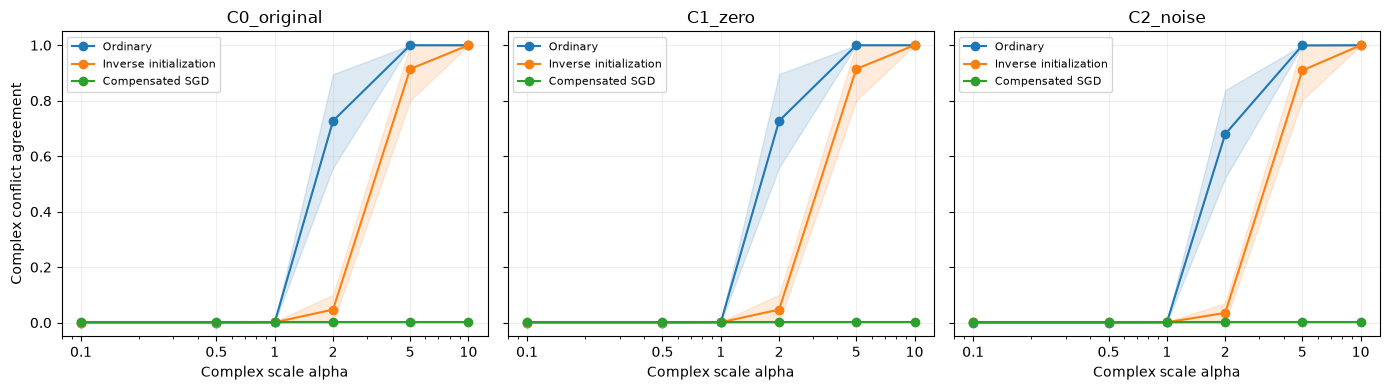

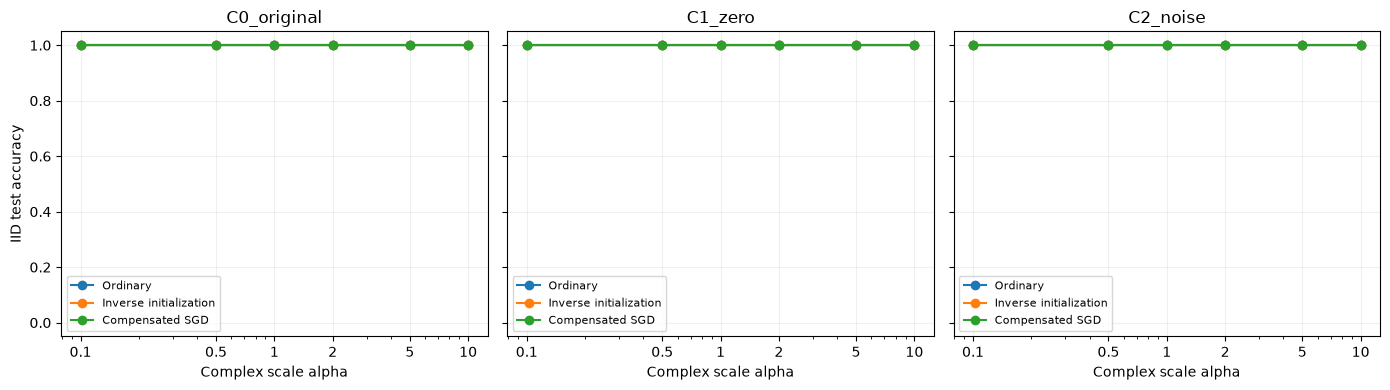

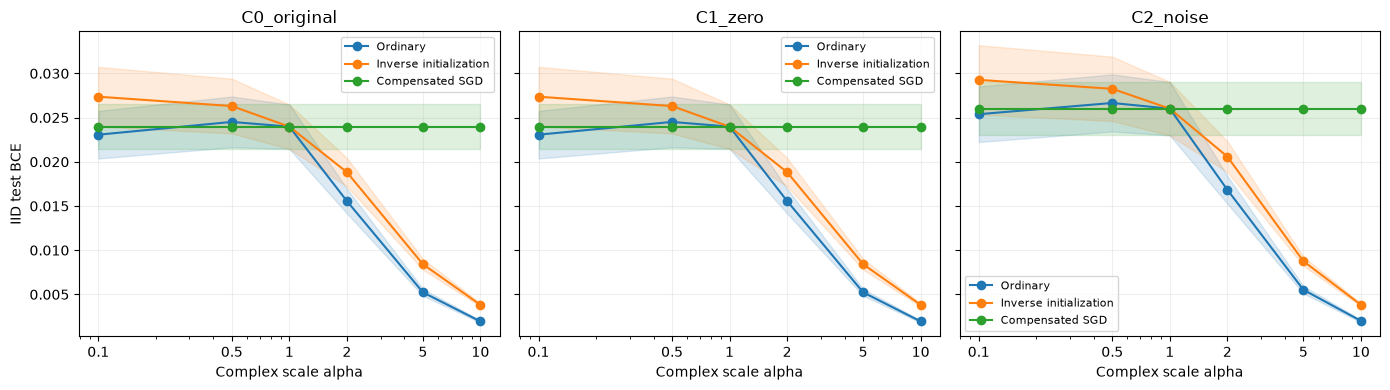

In [3]:
labels = {'ordinary':'Ordinary','inverse_init':'Inverse initialization','compensated_sgd':'Compensated SGD'}
colors = {'ordinary':'tab:blue','inverse_init':'tab:orange','compensated_sgd':'tab:green'}
def scale_panels(metric, title, filename, bounded=True):
    fig, axes = plt.subplots(1,3,figsize=(14,4),sharey=True)
    for ax,dataset in zip(axes,DATASETS):
        for condition in CONDITIONS:
            group = final[(final.dataset==dataset)&(final.condition==condition)].groupby('alpha')[metric].agg(['mean','std'])
            x, m = group.index.to_numpy(), group['mean'].to_numpy()
            sd = group['std'].fillna(0).to_numpy()
            lower,upper = m-sd,m+sd
            if bounded: lower,upper=lower.clip(0,1),upper.clip(0,1)
            ax.plot(x,m,'o-',label=labels[condition],color=colors[condition])
            ax.fill_between(x,lower,upper,color=colors[condition],alpha=0.15)
        ax.set_xscale('log'); ax.set_xticks(metadata['alphas'],labels=[f'{a:g}' for a in metadata['alphas']])
        ax.set(title=dataset,xlabel='Complex scale alpha')
        if bounded: ax.set_ylim(-0.05,1.05)
        ax.grid(alpha=0.2); ax.legend(fontsize=8)
    axes[0].set_ylabel(title)
    fig.tight_layout(); fig.savefig(FIGURES / filename,dpi=180); plt.show()
scale_panels('complex_conflict_agreement','Complex conflict agreement','conflict_reliance.png')
scale_panels('test_accuracy','IID test accuracy','test_accuracy.png')
scale_panels('test_loss','IID test BCE','test_loss.png',bounded=False)

## 2 Paired effect of adding active noise
Subtract C1 from C2 within the same seed, scale, and training condition.
Positive conflict differences mean more complex agreement with noise.
Negative test accuracy differences mean worse generalization with noise.
Do not confuse an average change with consistent change in every seed.

In [4]:
metrics = ['complex_conflict_agreement','test_accuracy','test_loss',
           'test_simple_probability_change','test_complex_probability_change']
left = final[final.dataset=='C1_zero'].set_index(['condition','alpha','seed'])[metrics]
right = final[final.dataset=='C2_noise'].set_index(['condition','alpha','seed'])[metrics]
paired = right-left
display(paired)
display(paired.groupby(['condition','alpha']).agg(['mean','std']))
paired.to_csv(RESULTS / 'paired_noise_effects.csv')
aggregate = final.groupby(['dataset','condition','alpha'])[metrics].agg(['mean','std'])
aggregate.to_csv(RESULTS / 'aggregate_summary.csv')

complex_conflict_agreement  test_accuracy  \
condition       alpha seed                                              
ordinary        0.1   42                      0.000000            0.0   
                0.5   42                      0.000000            0.0   
                1.0   42                      0.000000            0.0   
                2.0   42                     -0.099121            0.0   
                5.0   42                      0.000000            0.0   
...                                                ...            ...   
compensated_sgd 0.5   46                      0.000000            0.0   
                1.0   46                      0.000000            0.0   
                2.0   46                      0.000000            0.0   
                5.0   46                      0.000000            0.0   
                10.0  46                      0.000000            0.0   

                            test_loss  test_simple_probability_change  \
condition       alpha seed                                              
ordinary        0.1   42     0.003653                       -0.006299   
                0.5   42     0.003615                       -0.006192   
                1.0   42     0.003503                        0.017495   
                2.0   42     0.002341                        0.046616   
                5.0   42     0.000574                        0.003301   
...                               ...                             ...   
compensated_sgd 0.5   46     0.001432                        0.000816   
                1.0   46     0.001432                        0.000816   
                2.0   46     0.001432                        0.000816   
                5.0   46     0.001432                        0.000816   
                10.0  46     0.001432                        0.000816   

                            test_complex_probability_change  
condition       alpha seed                                   
ordinary        0.1   42                           0.000266  
                0.5   42                           0.000445  
                1.0   42                          -0.022327  
                2.0   42                          -0.048003  
                5.0   42                          -0.003635  
...                                                     ...  
compensated_sgd 0.5   46                          -0.003099  
                1.0   46                          -0.003099  
                2.0   46                          -0.003099  
                5.0   46                          -0.003099  
                10.0  46                          -0.003099  

[90 rows x 5 columns]

complex_conflict_agreement           test_accuracy       \
                                            mean       std          mean  std   
condition       alpha                                                           
compensated_sgd 0.1                     0.000098  0.000218           0.0  0.0   
                0.5                     0.000098  0.000218           0.0  0.0   
                1.0                     0.000098  0.000218           0.0  0.0   
                2.0                     0.000098  0.000218           0.0  0.0   
                5.0                     0.000098  0.000218           0.0  0.0   
                10.0                    0.000098  0.000218           0.0  0.0   
inverse_init    0.1                     0.001074  0.002140           0.0  0.0   
                0.5                     0.001074  0.002140           0.0  0.0   
                1.0                     0.000098  0.000218           0.0  0.0   
                2.0                    -0.012012  0.020137           0.0  0.0   
                5.0                    -0.005273  0.011131           0.0  0.0   
                10.0                   -0.000293  0.000655           0.0  0.0   
ordinary        0.1                     0.000000  0.000000           0.0  0.0   
                0.5                     0.000000  0.000000           0.0  0.0   
                1.0                     0.000098  0.000218           0.0  0.0   
                2.0                    -0.047852  0.030548           0.0  0.0   
                5.0                    -0.000684  0.001529           0.0  0.0   
                10.0                    0.000000  0.000000           0.0  0.0   

                      test_loss           test_simple_probability_change  \
                           mean       std                           mean   
condition       alpha                                                      
compensated_sgd 0.1    0.002037  0.000843                       0.008248   
                0.5    0.002037  0.000843                       0.008248   
                1.0    0.002037  0.000843                       0.008248   
                2.0    0.002037  0.000843                       0.008248   
                5.0    0.002037  0.000843                       0.008248   
                10.0   0.002037  0.000843                       0.008248   
inverse_init    0.1    0.001905  0.000876                       0.003122   
                0.5    0.001952  0.000855                       0.004290   
                1.0    0.002037  0.000843                       0.008248   
                2.0    0.001762  0.000570                       0.018859   
                5.0    0.000340  0.000135                      -0.004002   
                10.0   0.000010  0.000056                      -0.001467   
ordinary        0.1    0.002317  0.000766                      -0.004327   
                0.5    0.002142  0.000912                      -0.003321   
                1.0    0.002037  0.000843                       0.008248   
                2.0    0.001277  0.000602                       0.024641   
                5.0    0.000293  0.000179                       0.001807   
                10.0   0.000061  0.000049                       0.000109   

                                test_complex_probability_change            
                            std                            mean       std  
condition       alpha                                                      
compensated_sgd 0.1    0.006219                       -0.011460  0.007200  
                0.5    0.006219                       -0.011460  0.007200  
                1.0    0.006219                       -0.011460  0.007200  
                2.0    0.006219                       -0.011460  0.007200  
                5.0    0.006219                       -0.011460  0.007200  
                10.0   0.006219                       -0.011460  0.007200  
inverse_init    0.1    0.002077        

## 3 Prediction interventions
Flip AT or negate one complex coordinate; preserve R and all magnitudes.
Hard flips measure class changes. Absolute probability changes also detect
responses that do not cross the decision threshold. Neither is calibration.
Conflict probes and test interventions use different magnitude draws, so their
scores may differ despite covering the same contradictory sign regions.

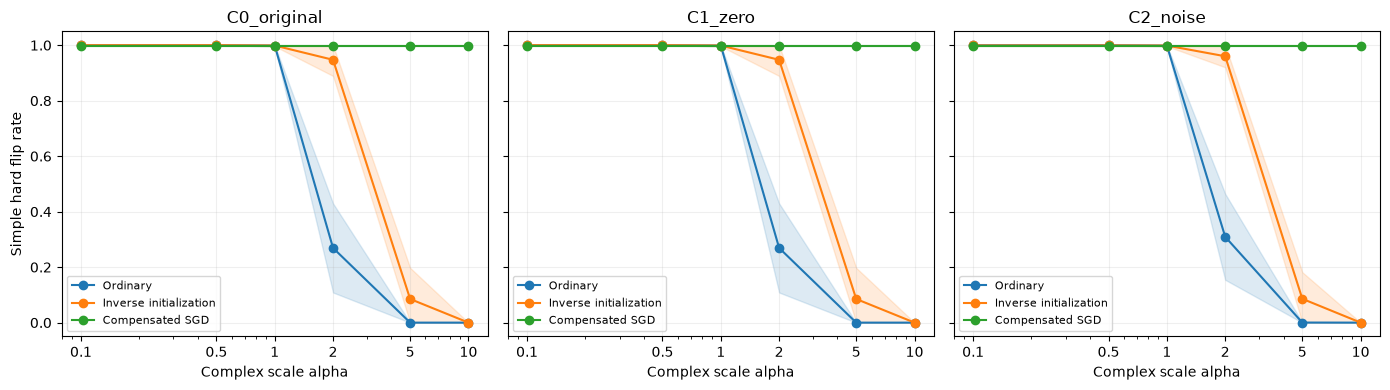

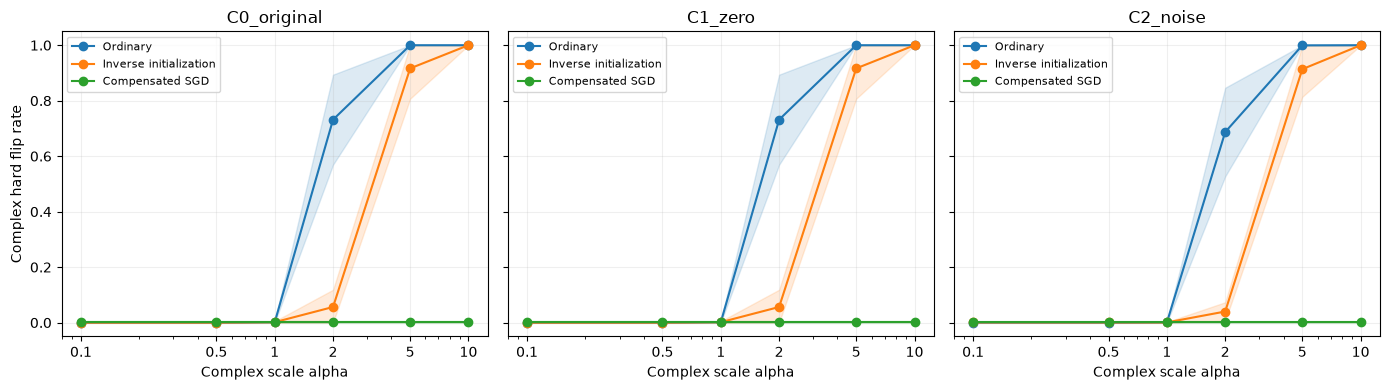

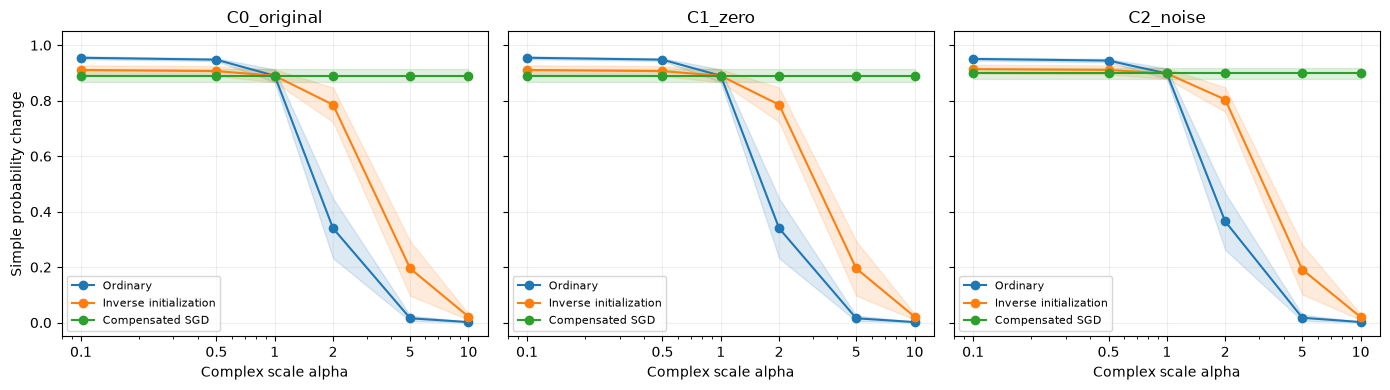

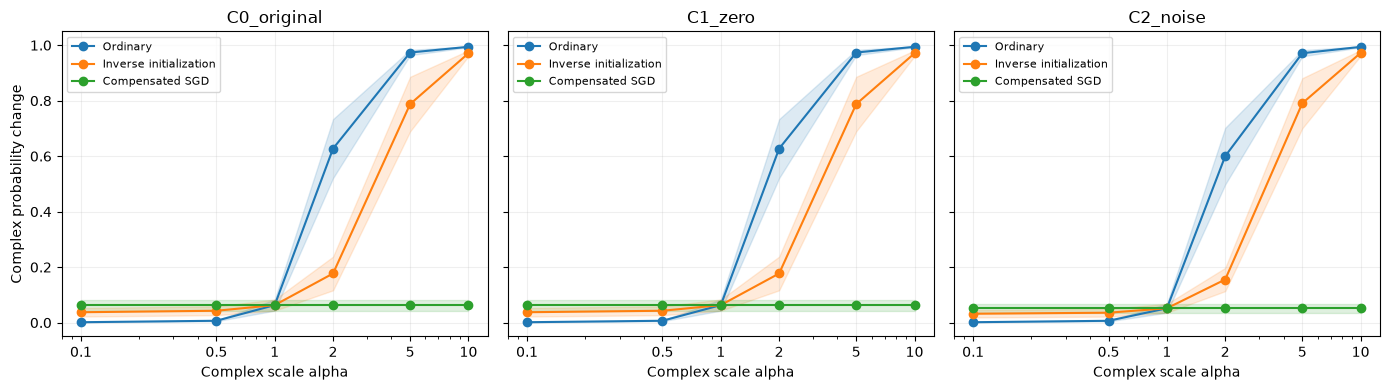

In [5]:
for metric,title in [('test_simple_flip_rate','Simple hard flip rate'),
                     ('test_complex_flip_rate','Complex hard flip rate'),
                     ('test_simple_probability_change','Simple probability change'),
                     ('test_complex_probability_change','Complex probability change')]:
    scale_panels(metric,title,metric+'.png')

## 4 Training trajectories and numerical controls
Preference can continue changing after aligned-data accuracy reaches 100%.
Compare the logged trajectories; do not infer exact feature learning times
between 25-update checkpoints. Numerical equivalence is an algebraic control.

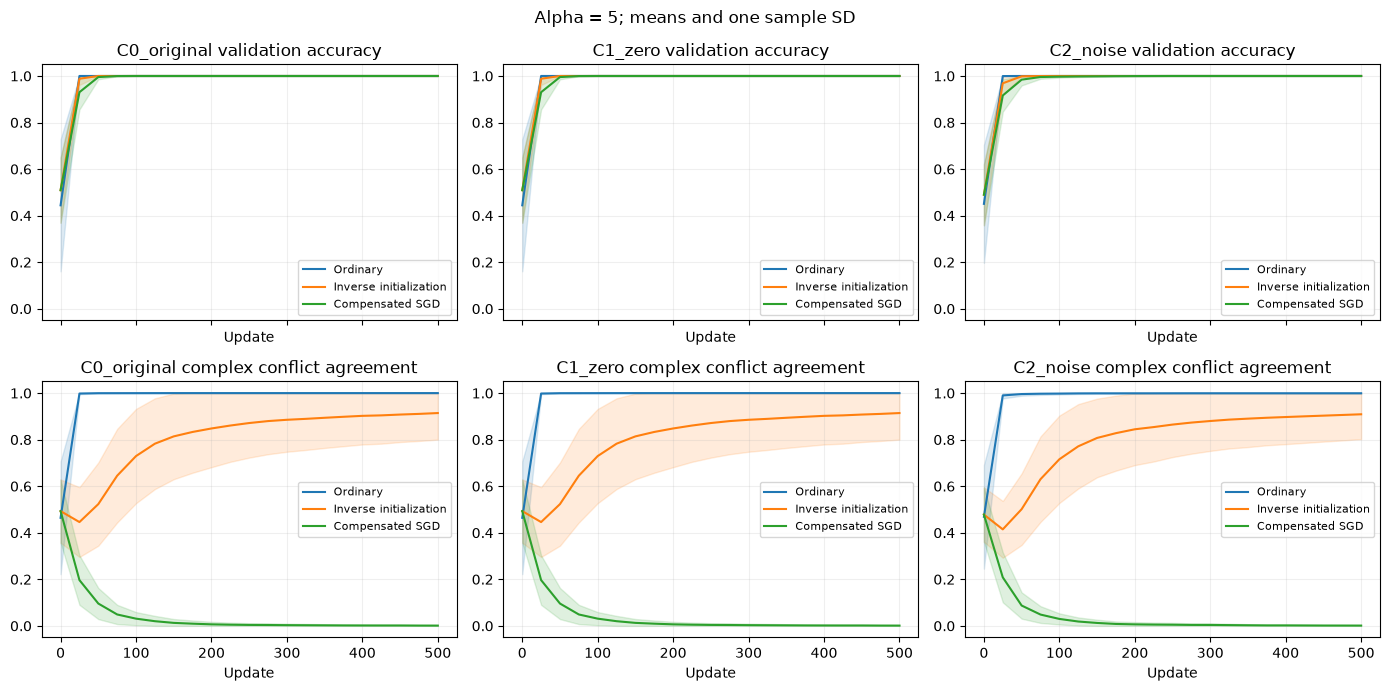

logit_error  parameter_error
dataset     check                                            
C0_original compensated_vs_unit     0.000003         0.000002
C1_zero     c1_vs_c0                0.000000         0.000000
            compensated_vs_unit     0.000003         0.000002
C2_noise    compensated_vs_unit     0.000006         0.000002

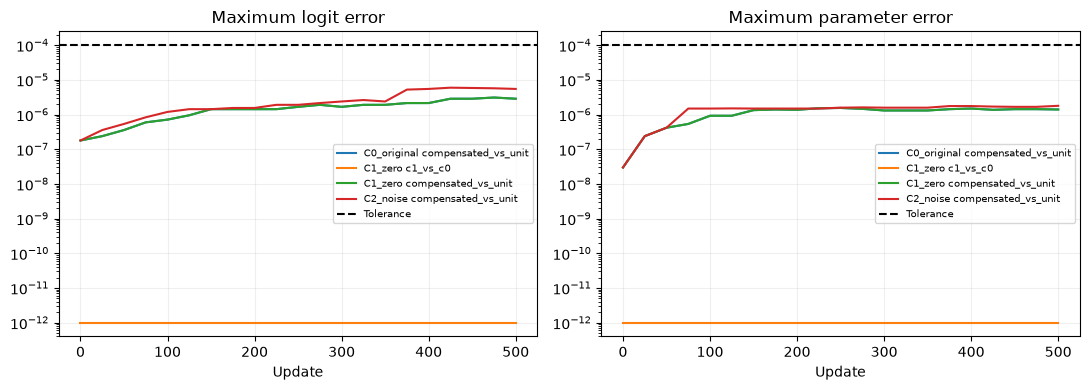

Exact zeros are plotted at 1e-12 only to display them on a logarithmic axis.


In [6]:
ALPHA_TO_VIEW = 5.0
assert ALPHA_TO_VIEW in metadata['alphas']
fig, axes = plt.subplots(2,3,figsize=(14,7),sharex=True)
for col,dataset in enumerate(DATASETS):
    for condition in CONDITIONS:
        subset = history[(history.dataset==dataset)&(history.condition==condition)&(history.alpha==ALPHA_TO_VIEW)]
        for row,metric in enumerate(['validation_accuracy','complex_conflict_agreement']):
            group = subset.groupby('step')[metric].agg(['mean','std'])
            m,sd=group['mean'].to_numpy(),group['std'].fillna(0).to_numpy()
            ax=axes[row,col]
            ax.plot(group.index,m,label=labels[condition],color=colors[condition])
            ax.fill_between(group.index,(m-sd).clip(0,1),(m+sd).clip(0,1),alpha=0.15,color=colors[condition])
            ax.set(title=dataset+' '+metric.replace('_',' '),xlabel='Update',ylim=(-0.05,1.05))
            ax.grid(alpha=0.2); ax.legend(fontsize=8)
fig.suptitle(f'Alpha = {ALPHA_TO_VIEW:g}; means and one sample SD')
fig.tight_layout(); fig.savefig(FIGURES / 'training_trajectories.png',dpi=180); plt.show()
display(checks.groupby(['dataset','check'])[['logit_error','parameter_error']].max())
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric in zip(axes,['logit_error','parameter_error']):
    for (dataset,check),group in checks.groupby(['dataset','check']):
        maximum=group.groupby('step')[metric].max()
        ax.plot(maximum.index,maximum.clip(lower=1e-12),label=dataset+' '+check)
    ax.axhline(metadata['trajectory_tolerance'],color='black',linestyle='--',label='Tolerance')
    ax.set_yscale('log'); ax.set(title='Maximum '+metric.replace('_',' '),xlabel='Update')
    ax.legend(fontsize=7); ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(FIGURES / 'trajectory_checks.png',dpi=180); plt.show()
print('Exact zeros are plotted at 1e-12 only to display them on a logarithmic axis.')

## 5 Conclusions to derive after running
- Do C0 and C1 match numerically, as the inactive-coordinate argument predicts?
- Does C2 retain the reversal at large alpha, including under inverse initialization?
- How much does C2 change preference relative to C1 within each seed?
- Does noise reduce held out accuracy or change confidence even if accuracy is unchanged?
- Does compensated SGD preserve each condition's own unit scale function?

Do not claim that nominal dimensionality equals informative dimensionality, or
that noise independence in the generator guarantees zero finite-sample correlation.
One fixed dataset draw and five initialization seeds do not quantify dataset
uncertainty. Conflict behavior remains outside the aligned training support.
Multiple nonlinear rules remain a separate future experiment.